# Probability, Information, and Decisions

## 1. Introduction and learning objectives

A predictive distribution, a fitted parameter, and an action solve related but distinct problems. This chapter connects the probability and evaluation work in Stages 00–01 to classical classifiers and later neural objectives. You will derive proper probability losses, distinguish likelihood from posterior prediction, calculate information quantities, and choose decisions under an explicit cost.

Prerequisites are conditional probability, derivatives, matrix shapes, stable logarithms, and the Stage 01 train/validation/test protocol. Calculus is applied directly. The common convention is natural logarithms and information measured in **nats**. Divide a result in nats by log(2) to express it in bits.

**Diagnostic:** attempt the first two tasks before reading. Later exercises introduce new connections, even if entropy and softmax are already familiar. The unit's small arrays run on CPU; study time belongs to reasoning and experiments rather than large training runs.

**Study workflow:** attempt each dedicated answer first, then reveal its hint or worked solution. Reference Python is displayed Markdown and is not executed by Run All. Snippet dependencies refer only to this chapter.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

### Exercise 02.01.01 — Separate forecasts from actions

**Type:** Conceptual · **Answer:** Markdown

A detector outputs p=P(Y=1 | x). Explain why the same p might lead to different actions in two applications. Which quantities come from the statistical model, which from the decision specification, and which require evaluation data?

**Expected outcome:** distinguish conditional probability, action cost, and evidence about predictive/decision quality.

**Your response to Exercise 02.01.01**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.01.01**

Changing a false-negative cost does not automatically change the conditional event being predicted.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.01.01**

The model estimates a conditional distribution for a specified population. A decision rule combines that distribution with the costs of available actions. With different error costs, the same forecast can rationally produce different actions. Held-out observations assess probability quality and realized decision performance under the sampling assumptions. A cost specification is not learned merely by maximizing likelihood, and a model score is not necessarily a calibrated probability.

</details>

### Exercise 02.01.02 — Calculate the excess probability loss

**Type:** Numerical · **Answer:** Markdown

For p=(.25,.75) and q=(.5,.5), calculate H(p), cross-entropy H(p,q), and KL(p||q) in nats. Express the entropy in bits and identify the extra expected log loss caused by using q.

**Expected outcome:** three scalar values and the identity H(p,q)=H(p)+KL(p||q).

**Your response to Exercise 02.01.02**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.01.02**

Use the event frequencies p to weight both expectations, including the loss of predictions q.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.01.02**

H(p)=−.25 log(.25)−.75 log(.75)≈.562335145 nats, or .811278124 bits. Cross-entropy is −log(.5)=.693147181 nats. KL is approximately .130812036 nats, the excess expected log loss relative to forecasting p. These are expectations under the specified p, not estimates from a finite test sample.

</details>

## 2. Prerequisites and mathematical foundations

### Conditional risk makes the target explicit

Given an action a and loss ℓ(a,y), conditional risk is R(a | x)=E[ℓ(a,Y) | X=x]. A Bayes action minimizes this expectation under the conditional distribution. Under squared loss, expand E[(a−Y)² | x]=(a−E[Y | x])²+Var(Y | x), so the conditional mean minimizes risk. Absolute loss is minimized by a conditional median. Zero-one classification loss is minimized by a most-probable class. These statements concern a known distribution; fitting it from limited data is an additional problem.

For a cost matrix C with rows indexing actions and columns indexing true classes, and posterior vector p, the action risks are C p. Nonnegative finite costs are used here. The smallest risk determines an action; equal risks require a declared tie convention. Probabilities, class labels, costs, and action indices must retain consistent ordering.

For binary errors with false-positive cost c_FP and false-negative cost c_FN, predicting 1 costs c_FP(1−p), while predicting 0 costs c_FN p. With positive total cost, the boundary is

$$t=\frac{c_{\rm FP}}{c_{\rm FP}+c_{\rm FN}}.$$

Choose 1 for p>t and 0 for p<t. Either is optimal at equality; our generic action implementation breaks ties by lowest action index. The Stage 01 metrics use p≥t as their explicitly chosen decision convention. Both can be consistent with equal expected costs at a tie.

### Likelihood, posterior, and predictive distribution

For iid training rows, likelihood multiplies observation probabilities/densities at fixed parameters θ. MLE maximizes this product, or minimizes its negative log. MAP adds a prior density and maximizes a posterior density in the stated parameterization. A posterior predictive distribution integrates predictions over parameter uncertainty:

$$p(y_*\mid x_*,D)=\int p(y_*\mid x_*,\theta)\,p(\theta\mid D)\,d\theta.$$

A prediction at a MAP parameter is generally different from that integral. Density can exceed one, so continuous-data negative log-likelihood need not be nonnegative. The discrete entropy formulas below do not directly specify differential entropy or its behavior under a change of units.

## 3. Theoretical development and worked examples

### Information quantities and proper log loss

For probability vectors p and q over the same finite categories,

$$H(p)=-\sum_k p_k\log p_k,\quad
H(p,q)=-\sum_k p_k\log q_k,\quad
D_{\rm KL}(p\|q)=\sum_k p_k\log\frac{p_k}{q_k}.$$

Use 0 log 0=0 by continuity. If p_k>0 and q_k=0, cross-entropy and KL are infinite. Algebra gives H(p,q)=H(p)+KL(p||q). To see KL≥0 when all required q entries are positive, use log u≤u−1:

$$-\sum_{p_k>0}p_k\log(q_k/p_k)
\geq 1-\sum_{p_k>0}q_k\geq0.$$

Equality requires q=p. Therefore truthful probabilities minimize expected log loss. This is a population statement. An empirical average is noisy; minimizing it over many candidates can select an optimistic result. KL is asymmetric and is not generally a metric.

For a joint discrete distribution P(X,Y), mutual information is

$$I(X;Y)=\sum_{x,y:P(x,y)>0}P(x,y)\log\frac{P(x,y)}{P(x)P(y)}
=H(X)+H(Y)-H(X,Y).$$

It is KL from the joint distribution to the product of its marginals, hence nonnegative and zero exactly at independence in this finite setting. High mutual information measures statistical dependence under that distribution; it does not establish a causal relationship, a useful deployment representation, or a model's truthfulness.

### Categorical logits and their derivatives

For K classes, logits z∈R^K define q_k=exp(z_k)/Σ_j exp(z_j). With observed class y, negative log-likelihood is log Σ_j exp(z_j)−z_y. Subtracting max(z) before exponentiation preserves probabilities and avoids ordinary exponential overflow. Compute the log probability from the shifted logits directly, so underflow of an extremely small rounded q does not turn a representable log loss into log(0).

Differentiating gives the Jacobian ∂q/∂z=diag(q)−qqᵀ and loss gradient q−one_hot(y). For n observations, put the mean factor 1/n in that output sensitivity once. Adding the same constant to every class logit leaves q and the loss unchanged; the gradient's class components consequently sum to zero.

For logits Z=XW+b, shapes are X(n,d), W(d,K), b(K,), labels(n,). If G=(Q−Y_onehot)/n, then ∇_W J=XᵀG+λW and ∇_b J=Σ_i G_i for mean categorical loss plus λ||W||²_F/2. The intercept is unpenalized. This is a linear classifier; learning nonlinear features changes the optimization geometry.

### Exercise 02.01.03 — Derive a cost-sensitive decision

**Type:** Mathematical · **Answer:** Markdown

Derive the threshold for c_FP=1 and c_FN=3. Decide at p=.2 and .4. What happens at the boundary, and which assumption is required to interpret these as expected costs?

**Expected outcome:** two risk calculations and an explicit tie/forecast interpretation.

**Your response to Exercise 02.01.03**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.01.03**

Compare the two expected action costs, not a metric averaged across an unrelated dataset.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.01.03**

The threshold is 1/4. At p=.2, action 1 costs .8 and action 0 costs .6, so choose 0. At p=.4, their costs are .6 and 1.2, so choose 1. At p=.25 both cost .75; either action minimizes risk, with the implementation's tie policy deciding. The p values must describe the relevant conditional outcome probabilities and costs must reflect the intended decision. An uncalibrated score or changed population can invalidate that interpretation.

</details>

### Exercise 02.01.04 — Connect MAP to the mean ridge objective

**Type:** Mathematical · **Answer:** Markdown

Assume Gaussian observation noise with known variance σ² and prior w∼N(0,τ²I), with the intercept held fixed for this derivation. Derive the relationship between σ², τ², n, and λ in half-MSE+λ||w||²/2. Explain what holding λ fixed as n changes implies about this prior interpretation.

**Expected outcome:** the n-dependent relationship and a distinction between duplicated rows and independent new observations.

**Your response to Exercise 02.01.04**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.01.04**

Start with the summed negative log posterior, then multiply the whole objective by σ²/n.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.01.04**

Ignoring parameter-independent constants, the summed objective is ||Xw+b−y||²/(2σ²)+||w||²/(2τ²). Multiplying by σ²/n gives half-MSE+σ²||w||²/(2nτ²), so λ=σ²/(nτ²). A fixed prior variance therefore corresponds to a λ that decreases as independent sample size grows. Holding λ fixed while n changes corresponds to changing this prior precision. Mechanically duplicated rows are not additional independent statistical evidence, even though their mean objective is unchanged. A proper prior on a free intercept would contribute its own term; this derivation conditions on b.

</details>

## 4. Guided exercises

### Exercise 02.01.05 — Calculate dependence with two joint tables

**Type:** Numerical · **Answer:** Markdown

Compute H(X), H(Y), H(X,Y), and I(X;Y) for P₁=[[.5,0],[0,.5]] and P₂=[[.25,.25],[.25,.25]]. Explain the role of zero entries without taking log(0).

**Expected outcome:** exact multiples of log 2 and an independence interpretation.

**Your response to Exercise 02.01.05**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.01.05**

Both marginals are uniform in both examples; the joint uncertainty differs.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.01.05**

For P₁, H(X)=H(Y)=H(X,Y)=log 2, so I=log 2. Y is determined by X. For P₂, H(X)=H(Y)=log 2 and H(X,Y)=log 4, so I=0 and the variables are independent. Zero-probability joint outcomes contribute zero by continuity. Their logarithms should be omitted by a mask, not multiplied as zero times negative infinity in floating point.

</details>

### Exercise 02.01.06 — Choose what to evaluate

**Type:** Conceptual · **Answer:** Markdown

Two forecasts always choose the same most-probable class but assign different probabilities. Give a decision metric and a probability metric that can behave differently. Explain why minimizing output entropy is not automatically a good learning objective for correct predictions.

**Expected outcome:** separate uncertainty in a forecast from agreement with outcomes.

**Your response to Exercise 02.01.06**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.01.06**

A confident wrong forecast can have low entropy and very high log loss.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.01.06**

Their zero-one accuracy can be identical while their log loss or Brier score differs. Entropy summarizes the forecast distribution itself and does not compare it with observed outcomes. A point mass on the wrong class has zero entropy and maximal zero-one error; its discrete log loss is infinite when the true class was assigned probability zero. Calibration and accuracy require outcome evidence, not confidence alone.

</details>

## 5. Implementation challenges

### Exercise 02.01.07 — Calculate entropy, cross-entropy, and KL safely

**Type:** Programming · **Answer:** Code

Implement `information_losses(p,q)` for equal nonempty probability vectors, accepting zeros. Reject negatives, nonfinite entries, shape mismatches, and unnormalized vectors. Return entropy, cross-entropy, KL in nats. Do not silently clip or renormalize.

**Expected outcome:** the diagnostic values, exact zero contributions, and infinity for missing q support.

In [ ]:
# Your code for Exercise 02.01.07.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.01.07**

Mask by p>0 before logarithms; handle a required zero q explicitly.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.01.07**

The helper is shared with the next information reference. The normalization tolerance covers floating-point summation, not arbitrary weights. Infinity is the mathematical result for missing support, not an implementation failure to replace silently with a finite score.

~~~python
def probability_vector(p):
    p = np.asarray(p, dtype=float)
    if p.ndim != 1 or p.size == 0 or not np.isfinite(p).all() or np.any(p < 0):
        raise ValueError("finite nonnegative vector required")
    if not np.isclose(p.sum(), 1., rtol=1e-12, atol=1e-12):
        raise ValueError("probabilities must sum to one")
    return p

def information_losses(p, q):
    p, q = probability_vector(p), probability_vector(q)
    if p.shape != q.shape:
        raise ValueError("category shape mismatch")
    active = p > 0
    entropy = -float(p[active] @ np.log(p[active]))
    if np.any(q[active] == 0):
        return entropy, np.inf, np.inf
    cross = -float(p[active] @ np.log(q[active]))
    divergence = float(p[active] @ (np.log(p[active]) - np.log(q[active])))
    return entropy, cross, divergence
~~~

</details>

### Exercise 02.01.08 — Calculate joint information

**Type:** Programming · **Answer:** Code

Implement `joint_information(P)` for a nonempty finite two-dimensional joint probability table. Return H(X), H(Y), H(X,Y), and mutual information. Support zero rows/columns. Avoid forming tiny products of marginal probabilities before taking logs.

**Expected outcome:** both hand tables and the identity I=H(X)+H(Y)−H(X,Y), within tolerance.

In [ ]:
# Your code for Exercise 02.01.08.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.01.08**

For a positive joint entry both marginals are positive. Subtract their logarithms instead of logging their product.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.01.08**

This depends on `probability_vector`. Entries with zero mass are omitted. The direct log-ratio calculation provides a useful cross-check against the difference-of-entropies identity, which can suffer cancellation near independence.

~~~python
def joint_information(P):
    P = np.asarray(P, dtype=float)
    if P.ndim != 2 or min(P.shape) == 0:
        raise ValueError("nonempty joint matrix required")
    probability_vector(P.ravel())
    px, py = P.sum(axis=1), P.sum(axis=0)
    hx = -float(px[px > 0] @ np.log(px[px > 0]))
    hy = -float(py[py > 0] @ np.log(py[py > 0]))
    rows, cols = np.nonzero(P > 0); mass = P[rows, cols]
    hxy = -float(mass @ np.log(mass))
    information = float(mass @ (np.log(mass) - np.log(px[rows]) - np.log(py[cols])))
    return hx, hy, hxy, information
~~~

</details>

### Exercise 02.01.09 — Differentiate stable categorical log loss

**Type:** Programming · **Answer:** Code

Implement `categorical_nll(logits,labels)` returning mean log loss, probabilities, and gradient with respect to logits. Require logits(n,K), n≥1,K≥2 and an integer label vector in range. Reject nonfinite inputs and unrepresentable shifted differences. Check extreme logits ±1000, additive-logit-shift invariance, and n=1.

**Expected outcome:** finite log loss for an extremely unlikely observed class, correct gradient shape, and class-gradient sums zero.

In [ ]:
# Your code for Exercise 02.01.09.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.01.09**

Compute log probabilities before exponentiating; do not recover log probabilities from rounded probabilities.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.01.09**

An independent derivative check can use a small moderate-logit objective computed as explicit exponentials and a scalar log. Extreme logits instead use exact two-class expectations. A represented probability may underflow to zero while its represented log probability remains finite.

~~~python
def categorical_nll(logits, labels):
    z, labels = np.asarray(logits, float), np.asarray(labels)
    if z.ndim != 2 or z.shape[0] == 0 or z.shape[1] < 2 or not np.isfinite(z).all():
        raise ValueError("finite nonempty logit matrix with K >= 2 required")
    if labels.shape != (len(z),) or not np.issubdtype(labels.dtype, np.integer):
        raise ValueError("integer label vector required")
    if np.any((labels < 0) | (labels >= z.shape[1])):
        raise ValueError("label outside class range")
    with np.errstate(over="ignore", invalid="ignore"):
        shifted = z - z.max(axis=1, keepdims=True)
    if not np.isfinite(shifted).all():
        raise FloatingPointError("logit differences exceed floating-point range")
    logp = shifted - np.log(np.exp(shifted).sum(axis=1, keepdims=True))
    probability = np.exp(logp)
    gradient = probability.copy()
    gradient[np.arange(len(z)), labels] -= 1
    gradient /= len(z)
    return float(-np.mean(logp[np.arange(len(z)), labels])), probability, gradient
~~~

</details>

### Exercise 02.01.10 — Connect categorical loss to an affine classifier

**Type:** Programming · **Answer:** Code

Implement `categorical_affine_loss(X,labels,W,b,penalty=0.)`. Use mean categorical NLL plus λ||W||²_F/2 and unpenalized biases. Return objective, weight gradient, bias gradient. Validate all shapes and check every parameter independently at a nonzero snapshot.

**Expected outcome:** no second observation average, no input mutation, and row-duplication invariance at fixed λ.

In [ ]:
# Your code for Exercise 02.01.10.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.01.10**

The gradient returned by categorical_nll already contains 1/n.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.01.10**

This depends on `categorical_nll`. The matrix product and bias sum accumulate sensitivities already normalized by n. The model is linear in features, making a useful bridge to the later neural multiclass chapter without requiring a neural training framework.

~~~python
def categorical_affine_loss(X, labels, W, b, penalty=0.):
    X, W, b = (np.asarray(a, float) for a in (X, W, b))
    if X.ndim != 2 or min(X.shape) == 0 or W.ndim != 2 or W.shape[0] != X.shape[1] or W.shape[1] < 2 or b.shape != (W.shape[1],):
        raise ValueError("expected X(n,d), W(d,K), b(K,) with K >= 2")
    if not all(np.isfinite(a).all() for a in (X, W, b)) or np.ndim(penalty) != 0 or not np.isfinite(penalty) or penalty < 0:
        raise ValueError("finite arrays and nonnegative scalar penalty required")
    loss, _, G = categorical_nll(X @ W + b, labels)
    return float(loss + penalty*np.sum(W**2)/2), X.T @ G + penalty*W, G.sum(axis=0)
~~~

</details>

### Exercise 02.01.11 — Choose actions from a cost matrix

**Type:** Programming · **Answer:** Code

Implement `bayes_actions(posterior,costs)` for posterior(n,K) and costs(A,K). Validate normalized finite nonnegative rows and costs. Return action indices and the (n,A) expected-risk matrix; equal risks choose the smallest action index.

**Expected outcome:** the binary worked example and a three-action case including an abstention action.

In [ ]:
# Your code for Exercise 02.01.11.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.01.11**

Multiply posterior by costs.T. Predicting a class is only one possible action design.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.01.11**

This depends on `probability_vector`. A third action could have a fixed abstention cost; its suitability depends on that specification. The code computes optimal actions under supplied distributions, not evidence that those distributions are correct.

~~~python
def bayes_actions(posterior, costs):
    posterior, costs = np.asarray(posterior, float), np.asarray(costs, float)
    if posterior.ndim != 2 or min(posterior.shape) == 0 or costs.ndim != 2 or costs.shape[0] == 0 or costs.shape[1] != posterior.shape[1]:
        raise ValueError("posterior(n,K) and costs(A,K) required")
    for row in posterior:
        probability_vector(row)
    if not np.isfinite(costs).all() or np.any(costs < 0):
        raise ValueError("finite nonnegative costs required")
    risks = posterior @ costs.T
    return np.argmin(risks, axis=1), risks
~~~

</details>

### Exercise 02.01.12 — Distinguish parameter and predictive uncertainty

**Type:** Programming · **Answer:** Code

Implement `normal_mean_posterior(values,noise_variance,prior_mean=0.,prior_variance=1.)` for iid normal observations with known noise variance and a normal mean prior. Return posterior mean, posterior variance, and posterior predictive variance for one new observation. Derive the conjugate update by completing the square.

**Expected outcome:** at observations [1,3], noise variance 1, prior N(0,1), return 4/3, 1/3, and 4/3 respectively.

In [ ]:
# Your code for Exercise 02.01.12.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.01.12**

Posterior precision is prior precision plus n times observation precision. Predictive variance also includes observation noise.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.01.12**

Completing the square gives v=(1/τ²+n/σ²)⁻¹ and m=v(m₀/τ²+Σx_i/σ²). Conditional Gaussian noise is independent of posterior parameter uncertainty, so predictive variance is σ²+v. This conjugate result does not imply arbitrary neural posterior inference has a closed form.

~~~python
def normal_mean_posterior(values, noise_variance, prior_mean=0., prior_variance=1.):
    values = np.asarray(values, float)
    if values.ndim != 1 or values.size == 0 or not np.isfinite(values).all():
        raise ValueError("nonempty finite observations required")
    if any(np.ndim(a) != 0 for a in (noise_variance, prior_mean, prior_variance)):
        raise ValueError("scalar model parameters required")
    if not np.isfinite([noise_variance, prior_mean, prior_variance]).all() or min(noise_variance, prior_variance) <= 0:
        raise ValueError("finite mean and positive variances required")
    precision = 1/prior_variance + len(values)/noise_variance
    if not np.isfinite(precision):
        raise FloatingPointError("precision exceeds floating-point range")
    variance = 1/precision
    mean = variance * (prior_mean/prior_variance + values.sum()/noise_variance)
    return float(mean), float(variance), float(noise_variance + variance)
~~~

</details>

## 6. Experiments and visualizations

The demonstration evaluates known scalar formulas. It does not implement the general reference functions. Compare a proper probability objective with action risks for a separate decision problem.

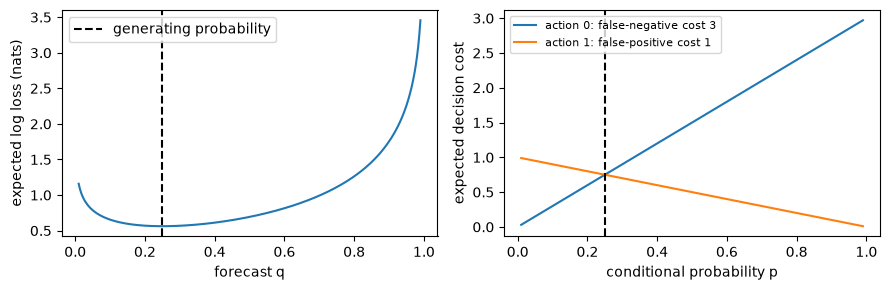

In [2]:
forecast = np.linspace(.01, .99, 300)
true_probability = .25
expected_logloss = -true_probability*np.log(forecast) - (1-true_probability)*np.log1p(-forecast)
fig, axes = plt.subplots(1, 2, figsize=(9, 3))
axes[0].plot(forecast, expected_logloss)
axes[0].axvline(true_probability, color="black", linestyle="--", label="generating probability")
axes[0].set(xlabel="forecast q", ylabel="expected log loss (nats)"); axes[0].legend()
axes[1].plot(forecast, 3*forecast, label="action 0: false-negative cost 3")
axes[1].plot(forecast, 1-forecast, label="action 1: false-positive cost 1")
axes[1].axvline(.25, color="black", linestyle="--")
axes[1].set(xlabel="conditional probability p", ylabel="expected decision cost"); axes[1].legend(fontsize=8)
fig.tight_layout(); plt.show()

### Exercise 02.01.13 — Compare a population objective with finite samples

**Type:** Experimental · **Answer:** Code

Generate Bernoulli labels with p=.25 for n=30 and 600, seed 201. Evaluate constant-forecast log loss on q∈[.02,.98] and compare with the exact population curve. Record empirical minimizers and repeat with seed 202. Do not use these illustrative samples as a repeatedly tuned final test set.

**Expected outcome:** actual curves and an explanation of sampling and grid-resolution effects.

In [ ]:
# Your code for Exercise 02.01.13.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.01.13**

The empirical constant optimum is the sample prevalence before discretizing q. A single sample's optimum need not equal the population p.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.01.13**

This experiment uses no reference implementation. It isolates finite-sample estimation of a fixed mathematical objective. A change of seed changes empirical prevalence and the curve; a denser grid changes the reported grid minimizer even with identical labels.

~~~python
grid = np.linspace(.02, .98, 241)
population = -.25*np.log(grid)-.75*np.log1p(-grid)
for seed in (201, 202):
    rng = np.random.default_rng(seed)
    for n in (30, 600):
        labels = rng.binomial(1, .25, n)
        losses = -labels.mean()*np.log(grid)-(1-labels.mean())*np.log1p(-grid)
        print(seed, n, 'prevalence / grid minimizer', labels.mean(), grid[np.argmin(losses)])
        plt.plot(grid, losses, alpha=.7, label=f'n={n}, seed={seed}')
plt.plot(grid, population, 'k--', label='population')
plt.xlabel('forecast q'); plt.ylabel('mean log loss (nats)'); plt.legend(); plt.show()
~~~

</details>

### Exercise 02.01.14 — Track posterior and predictive uncertainty

**Type:** Experimental · **Answer:** Code

Generate 32 iid normal observations with true mean .6 and noise variance 1 using seed 203. Compare prior variances .25 and 4 at sample sizes 2,8,32. Report posterior means, posterior standard deviations, and predictive standard deviations. Explain why the predictive variance does not tend to zero.

**Expected outcome:** a measured table/plot with prior sensitivity and observation noise distinguished.

In [ ]:
# Your code for Exercise 02.01.14.
# TODO: implement the task and record the requested checks or measurements.

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.01.14**

Use nested prefixes for this illustration and state that they are dependent, not independent repeats.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.01.14**

This depends on `normal_mean_posterior`. As n grows, parameter variance decreases, but a new noisy observation still has its own variance 1. This is a model-conditional calculation. The example does not establish interval coverage under misspecification or independence violations.

~~~python
observations = np.random.default_rng(203).normal(.6, 1., 32)
for prior_variance in (.25, 4.):
    means = []
    for n in (2, 8, 32):
        mean, variance, predictive = normal_mean_posterior(observations[:n], 1., prior_variance=prior_variance)
        means.append(mean)
        print(prior_variance, n, mean, np.sqrt(variance), np.sqrt(predictive))
    plt.plot([2,8,32], means, 'o-', label=f'prior variance {prior_variance}')
plt.axhline(.6, color='black', linestyle='--', label='generating mean')
plt.xlabel('training observations'); plt.ylabel('posterior mean'); plt.legend(); plt.show()
~~~

</details>

## 7. Interpretation and critical analysis

### Exercise 02.01.15 — Audit confidence and information claims

**Type:** Critical · **Answer:** Markdown

A model has lower output entropy after a change, and its representation has high mutual information with an identifier unique to each training row. The author claims both facts establish improved understanding and generalization. Identify what was measured and design a more informative evaluation.

**Expected outcome:** separate confidence, memorized dependence, predictive performance, and causal/semantic claims.

**Your response to Exercise 02.01.15**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.01.15**

Consider a confidently wrong classifier and a representation that simply stores the row identifier.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.01.15**

Output entropy measures uncertainty within the forecast, so reducing it can produce greater confidence without better outcomes. Mutual information with an identifier can reflect memorization and says little about a new row's task-relevant structure. Evaluate held-out probability losses, decisions under declared costs, calibration, controlled downstream tasks, and appropriately independent splits. Neither statistic by itself establishes causal reasoning, semantic understanding, or generalization. A theoretical information quantity also needs a stated estimator and finite-sample assumptions when measured from data.

</details>

### Exercise 02.01.16 — Read a primary source with a bounded question

**Type:** Critical · **Answer:** Markdown

Read Shannon's 1948 paper, Part I, Section 6 on choice, uncertainty, and entropy. Identify the probability experiment underlying its entropy definition and the logarithm's unit. Translate the definition into this chapter's notation. Construct a numerical counterexample to the claim that lower forecast entropy guarantees a correct prediction.

**Expected outcome:** a source/version note, equation translation, computed counterexample, and a limited supported conclusion using the paper-study template.

**Your response to Exercise 02.01.16**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.01.16**

Keep the communication-source uncertainty distinct from accuracy against an observed label. You need only the selected definition, not the full channel-coding results.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.01.16**

A suitable study records the reprinted original source and selected section, translates the finite alternatives and their probabilities to p_k, and explains the base-dependent information unit. For p=(1,0) and an observed class 1 (second category), forecast entropy is zero but the prediction is wrong; its unmodified log loss is infinite. This counterexample is independently checkable and establishes that forecast confidence alone does not imply correctness. It does not reproduce a communication theorem or adjudicate every possible definition of understanding.

</details>

## 8. Review questions and knowledge checks

### Exercise 02.01.17 — Explain curvature and a redundant logit direction

**Type:** Mathematical · **Answer:** Markdown

For one categorical observation, show that uᵀ[diag(q)−qqᵀ]u≥0 and that the all-ones vector is in its nullspace. What does this prove about convexity in logits, and what does it leave open about a multilayer neural network?

**Expected outcome:** a variance argument, shift invariance, and the scope of the convexity statement.

**Your response to Exercise 02.01.17**

_Write your reasoning, calculations, assumptions, and limitations here._

<details>
<summary>Show hint</summary>

**Hint — Exercise 02.01.17**

Treat u's coordinates as the values of a categorical random variable with probabilities q.

</details>

<details>
<summary>Show worked solution — try the exercise first</summary>

**Reference solution — Exercise 02.01.17**

The quadratic form is Σ_k q_k u_k²−(Σ_k q_k u_k)², the variance of those coordinate values under q, hence nonnegative. With all u_k=1 it is zero, and the matrix times the all-ones vector is q−q(qᵀ1)=0. The categorical NLL is convex in logits; common shifts are redundant. With fixed features and an affine model the data objective remains convex in its parameters, but composing it with learned nonlinear multilayer features does not establish convexity in all network weights.

</details>

## 9. Summary and next learning steps

Explain distributions and costs separately; derive proper losses, MAP scaling, and categorical gradients; implement support-aware information quantities and conjugate prediction; verify independent values and derivatives; evaluate finite-sample and prior effects; critique claims beyond those measurements.

Continue with the nearest-neighbor unit when it is published; the [Stage 02 guide](README.md) records readiness. Review [Stage 01 evaluation](../01-ml-fundamentals/evaluation-and-model-selection.ipynb) for data-use boundaries. Later chapters connect information losses to tree splits, latent-variable bounds, self-supervised objectives, and language modeling.

Primary reading: [Shannon, A Mathematical Theory of Communication (1948), reprint with corrections, Part I §6](https://people.math.harvard.edu/~ctm/home/text/others/shannon/entropy/entropy.pdf). Use the [paper-study template](../../docs/paper-study-template.md) to keep derivation, code verification, measured evidence, and interpretation separate. These exercises are original and do not reproduce an external course's assignment answers.